In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("superstore_sales.csv")

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:
print("Dataset shape:", df.shape)


print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

df.describe()

Dataset shape: (10800, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   obj

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [5]:
print(df.isnull().sum())

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [6]:
df = df.drop_duplicates()

categorical_cols = df.select_dtypes(
    include=['object']
).columns

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")


numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values handled.")
print(df.isnull().sum())

Missing values handled.
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [9]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    errors='coerce'
)


print("Invalid order dates:", df['Order Date'].isna().sum())

df = df.dropna(subset=['Order Date'])

print("After processing Invalid order dates:", df['Order Date'].isna().sum())

df['Year'] = df['Order Date'].dt.year

df['Year-Month'] = (
    df['Order Date'].dt.to_period('M')
)

print(df[['Order Date', 'Year', 'Year-Month']].head())

Invalid order dates: 0
After processing Invalid order dates: 0
  Order Date  Year Year-Month
0 2017-11-08  2017    2017-11
1 2017-11-08  2017    2017-11
2 2017-06-12  2017    2017-06
3 2016-10-11  2016    2016-10
4 2016-10-11  2016    2016-10


In [13]:
grouped_data = df.groupby('Sub-Category',
    as_index=False
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

grouped_data.head(10)

,Sub-Category,Sales,Profit
0,Accessories,167380.3180,41936.6357
1,Appliances,107532.1610,18138.0054
2,Art,27118.7920,6527.7870
3,Binders,203412.7330,30221.7633
4,Bookcases,114879.9963,-3472.5560
5,Chairs,328449.1030,26590.1663
6,Copiers,149528.0300,55617.8249
7,Envelopes,16476.4020,6964.1767
8,Fasteners,3024.2800,949.5182
9,Furnishings,91705.1640,13059.1436


In [14]:
grouped_data = df.groupby('Customer Name',
    as_index=False
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

grouped_data.head(10)

,Customer Name,Sales,Profit
0,Aaron Bergman,886.156,129.3465
1,Aaron Hawkins,1744.700,365.2152
2,Aaron Smayling,3050.692,-253.5746
3,Adam Bellavance,7755.620,2054.5885
4,Adam Hart,3250.337,281.1890
5,Adam Shillingsburg,3255.310,64.5374
6,Adrian Barton,14473.571,5444.8055
7,Adrian Hane,1735.514,-2.3146
8,Adrian Shami,58.820,21.8496
9,Aimee Bixby,966.710,313.6597


In [18]:
grouped = grouped_data.sort_values(by=["Sales"], ascending=False)
print("Top 10 Customers")
grouped.head(10)

Top 10 Customers


,Customer Name,Sales,Profit
686,Sean Miller,25043.050,-1980.7393
730,Tamara Chand,19052.218,8981.3239
622,Raymond Buch,15117.339,6976.0959
757,Tom Ashbrook,14595.620,4703.7883
6,Adrian Barton,14473.571,5444.8055
441,Ken Lonsdale,14175.229,806.8550
671,Sanjit Chand,14142.334,5757.4119
334,Hunter Lopez,12873.298,5622.4292
672,Sanjit Engle,12209.438,2650.6769
156,Christopher Conant,12129.072,2177.0493


In [19]:
grouped_data = df.groupby('Region',
    as_index=False
).agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

grouped_data.head(10)

,Region,Sales,Profit
0,Central,501239.8908,39706.3625
1,East,678781.2400,91522.7800
2,South,391721.9050,46749.4303
3,West,725457.8245,108418.4489


In [20]:
monthly_sales = (
    df.groupby('Year-Month', as_index=False)
      .agg(Total_Sales=('Sales', 'sum'))
)
monthly_sales.head()

,Year-Month,Total_Sales
0,2015-01,14236.895
1,2015-02,4519.892
2,2015-03,55691.009
3,2015-04,28295.345
4,2015-05,23648.287


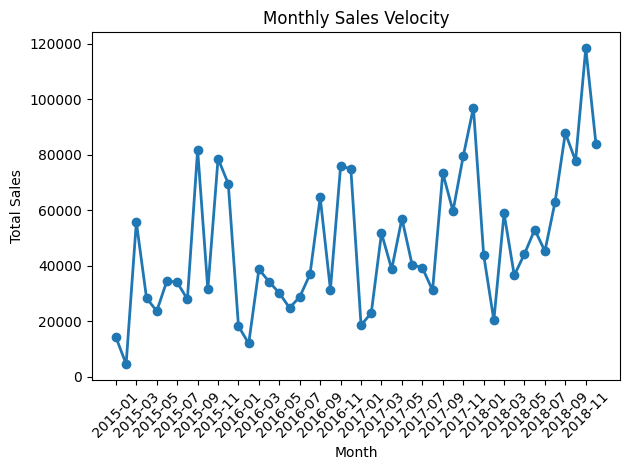

In [29]:
plt.plot(
    monthly_sales['Year-Month'].astype(str),
    monthly_sales['Total_Sales'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Velocity')
plt.xlabel('Month')
plt.ylabel('Total Sales')


plt.xticks(
    range(0, len(monthly_sales), 2),
    monthly_sales['Year-Month'].astype(str)[::2],
    rotation=45
)

plt.tight_layout()
plt.show()